## <h1> Student Depression Model <h1>

### The Student Depression dataset contains 27901 rows and 18 columns containing the following data :

#
#### Gender : Genre ( male / female)
#### Age : Age
#### City : Ville de residence
#### Profession : Profession (Student : etudiant)
#### Academic Pressure : Pression academique (0 - 10 )
#### Work Pressure : Pression professionnelle (0 - 10)
#### CGPA : Cumulative Grade Point Average (Moyenne générale cumulative)
#### Study satisfaction : Satisfaction academique (0 - 10)
#### Job Satisfaction : satisfaction professionnelle (0 - 10)
#### Sleep duration : Temps de sommeil 
#### Dietary habits : habitudes alimentaires (healthy - Moderate - ) 
#### Degree : Niveau d'etudes (B Pharm, Bsc, BA, BCA, M. Tech)
#### Have Suicidal thoughts ? : Pensee suicidaire (yes - No)
#### Work / Study hours : Heure d'etudes/ de travail
#### Financial stress : Stress financial (0 - 10)
#### Family history of mental illness : maladie mentale hereditaire (No - yes)
#### Depression : depression (0 - 1)


In [33]:
# Importation des bibliotheques

import numpy as np
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt 

import warnings
warnings.filterwarnings('ignore')


In [34]:
# Importing the dataset
data = pd.read_csv(r'D:\Documents\self learning\ML\Student Depression\Student_depression_analysis\data\raw\Student Depression Dataset.csv')

data.head()

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


## Basic information 

In [35]:
print("Basic information about the dataset:\n")
print("The dataset has {} rows and {} columns".format(data.shape[0], data.shape[1]))

print("\nColumn names (variables names):")
for col in data.columns:
    print(col)

print("\nData types of each column:\n")
print(data.dtypes)

print("\nCount of each data type in the dataset:\n")
print(data.dtypes.value_counts())


print("\nSummary statistics of the dataset:\n")
print(data.describe(include='all'))

print("\nDataset information:\n")
print(data.info())

Basic information about the dataset:

The dataset has 27901 rows and 18 columns

Column names (variables names):
id
Gender
Age
City
Profession
Academic Pressure
Work Pressure
CGPA
Study Satisfaction
Job Satisfaction
Sleep Duration
Dietary Habits
Degree
Have you ever had suicidal thoughts ?
Work/Study Hours
Financial Stress
Family History of Mental Illness
Depression

Data types of each column:

id                                         int64
Gender                                    object
Age                                      float64
City                                      object
Profession                                object
Academic Pressure                        float64
Work Pressure                            float64
CGPA                                     float64
Study Satisfaction                       float64
Job Satisfaction                         float64
Sleep Duration                            object
Dietary Habits                            object
Degree        

#### Missing values checking

In [36]:
print("\nCount of missing values in each column:\n")
print(data.isnull().sum())


Count of missing values in each column:

id                                       0
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         3
Family History of Mental Illness         0
Depression                               0
dtype: int64


#### Unique value checking

In [37]:
print("\nCount of unique values in each column:\n")
print(data.nunique())


Count of unique values in each column:

id                                       27901
Gender                                       2
Age                                         34
City                                        52
Profession                                  14
Academic Pressure                            6
Work Pressure                                3
CGPA                                       332
Study Satisfaction                           6
Job Satisfaction                             5
Sleep Duration                               5
Dietary Habits                               4
Degree                                      28
Have you ever had suicidal thoughts ?        2
Work/Study Hours                            13
Financial Stress                             5
Family History of Mental Illness             2
Depression                                   2
dtype: int64


#### Duplicates values checking

In [38]:
print("\nCount of duplicate rows in the dataset:\n")
print(data.duplicated().sum())


Count of duplicate rows in the dataset:

0


#### Outliers values checking

In [39]:
outliers = data[(np.abs(data['Age'] - data['Age'].mean()) > (3 * data['Age'].std()))]

print(f"\nCount of outliers in the dataset: {len(outliers)}")
print("\nOutliers in the dataset:\n")
print(outliers)


Count of outliers in the dataset: 19

Outliers in the dataset:

           id  Gender   Age         City Profession  Academic Pressure  \
1076     5569  Female  42.0       Rajkot    Student                2.0   
2909    14768  Female  58.0      Chennai    Student                4.0   
3436    17213    Male  49.0       Nagpur    Student                3.0   
4386    22004  Female  51.0       Bhopal    Student                2.0   
5537    27918  Female  44.0     Srinagar    Student                1.0   
6662    33392    Male  43.0       Rajkot    Student                5.0   
9006    45393    Male  46.0       Nashik    Student                1.0   
9238    46602    Male  59.0       Nashik    Student                1.0   
11532   58262    Male  42.0      Kolkata    Student                5.0   
13499   68441    Male  54.0         Agra    Student                5.0   
13618   69032  Female  48.0    Ghaziabad    Student                3.0   
14819   74887  Female  56.0     Ludhiana    Stu

In [40]:
cgpa_outliers = data[(np.abs(data['CGPA'] - data['CGPA'].mean()) > (3 * data['CGPA'].std()))]
print(f"\nCount of CGPA outliers in the dataset: {len(cgpa_outliers)}")
print("\nCGPA outliers in the dataset:\n")
print(cgpa_outliers)



Count of CGPA outliers in the dataset: 9

CGPA outliers in the dataset:

           id  Gender   Age       City Profession  Academic Pressure  \
4365    21880    Male  38.0    Chennai    Student                0.0   
10407   52737    Male  28.0   Vadodara    Student                3.0   
11489   58062  Female  32.0   Vadodara    Student                5.0   
13909   70453  Female  20.0  Ahmedabad    Student                0.0   
14855   75007    Male  21.0    Lucknow    Student                0.0   
20913  105773    Male  18.0  Ahmedabad    Student                0.0   
21805  110097    Male  34.0       Pune    Student                1.0   
25746  129756    Male  18.0     Rajkot    Student                0.0   
26719  134830  Female  24.0     Meerut    Student                0.0   

       Work Pressure  CGPA  Study Satisfaction  Job Satisfaction  \
4365             5.0   0.0                 0.0               4.0   
10407            0.0   0.0                 4.0               0.0   
1

## Graphiques de Visualisation des variables

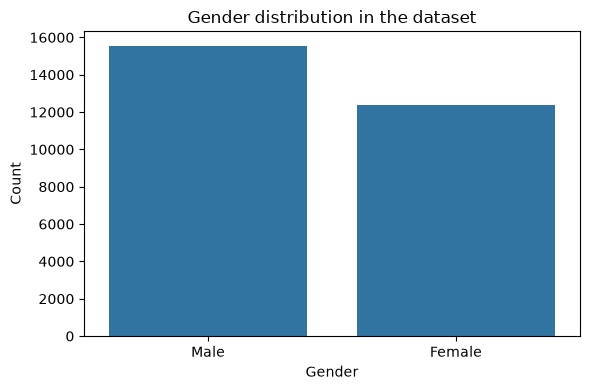

In [ ]:
# Genre distribution

fig, ax =  plt.subplots(figsize=(6, 4))
sns.countplot(x='Gender', data=data, ax=ax)
ax.set_title('Gender distribution in the dataset')
ax.set_xlabel('Gender')
ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

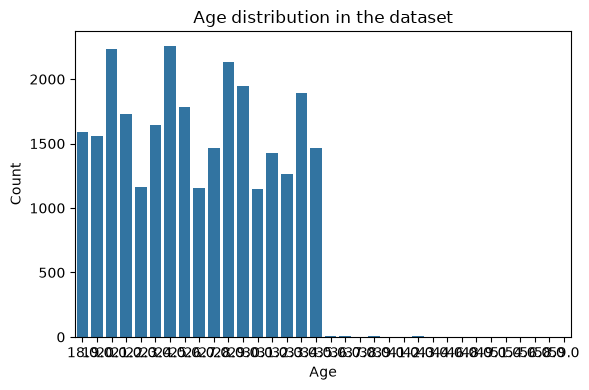

In [42]:
# Age distribution

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='Age', data=data, ax=ax)
ax.set_title('Age distribution in the dataset')
ax.set_xlabel('Age')
ax.set_ylabel('Count')

plt.tight_layout()
plt.show()